In [1]:
import sys
sys.path.append('../')

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
import seaborn as sns
import model
import json, csv
import mvpy
import plots

from copy import deepcopy

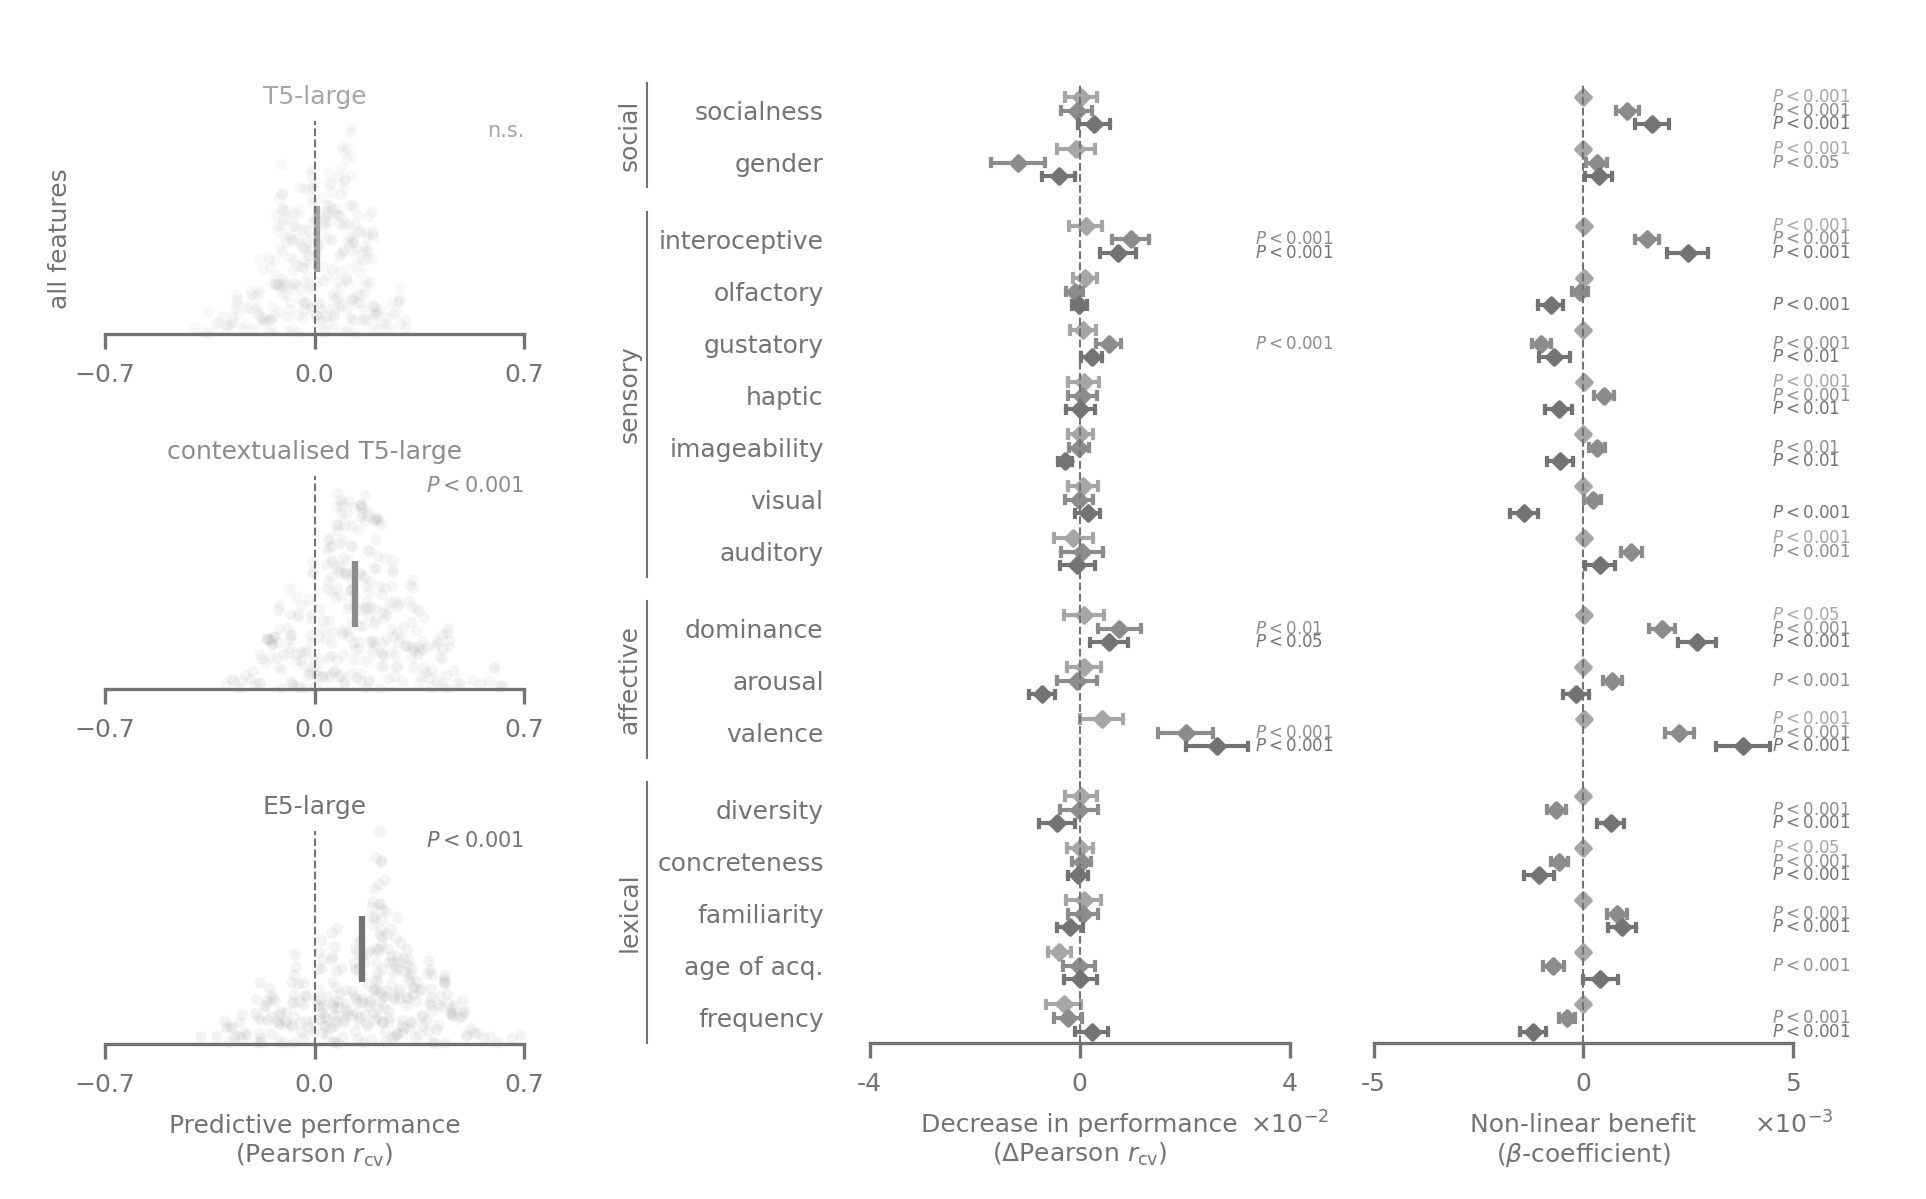

In [36]:
from typing import Optional
import matplotlib.image as mpimg
from matplotlib.offsetbox import OffsetImage, AnnotationBbox

import sys
sys.path.append('../')

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
import seaborn as sns
import model
import json, csv
import mvpy
import plots

from copy import deepcopy

exp = 2
run = 6
emb = 'glove'
compute_stat = False

mods = [
    't5-large',
    't5-large-context',
    'e5-large'
]

mods_label = [
    fr'T5-large',
    fr'contextualised T5-large',
    fr'E5-large',
]

cols = np.array([
    plots.colours.HL_EMBEDDING,
    plots.colours.HL_OTHERS,
    plots.colours.HL_SELF
])

hypothesis_test = 'sign'
hypothesis_alternative = 'two-sided'
hypothesis_method = 'holm'
hypothesis_se = 'within'

fig, ax = plt.subplots(figsize = (6.40, 4.0), dpi = 300)
ax.set_xlim([0, 1])
ax.set_ylim([0, 1])
ax.axis('off')

# panels B + C
ax3 = ax.inset_axes([0.450, 0.05, 0.225, 0.90])
ax4 = ax.inset_axes([0.720, 0.05, 0.225, 0.90])
axes = []

#cols_emb = np.array([
#    [131, 151, 207],
#    [170, 115, 159],
#    [218, 139, 105]
#]) / 255

#cols_emb = np.array([
#    [102,  83,  91],  # T5-large — dark rose-grey
#    [175, 141, 151],  # contextualised T5-large — dusty rose
#    [199, 112,  72],  # E5-large — terracotta
#]) / 255

cols_emb = np.array([
    [0.65, 0.65, 0.65],
    [0.55, 0.55, 0.55],
    [0.45, 0.45, 0.45]
])

for e_i, emb in enumerate(mods):
    outputs = torch.load(
        f'../data/ds-exp2/derivatives/run-00{run}/tasks/task-maspace_bse0-{emb}_mod-delta.pt', 
        map_location = torch.device('cpu'),
        weights_only = False
    )
    
    '''
    panel B + C
    '''

    # right panel
    perf = outputs['S3_r_full'][emb].mean(0)
    redu = (perf[None,:] - outputs['S3_r_redu'][emb].mean(1))
    mu1 = redu.mean(1)
    se1 = model.stats.bootstrap_se(redu.mT)
    if compute_stat:
        stat_p3 = model.stats.sample_tests(perf[None,:], popmean = 0.0, test = 'sign', alternative = 'greater', method = 'holm', se = 'between')
        stat_r3 = model.stats.sample_tests(redu, popmean = 0.0, test = 'sign', alternative = 'greater', method = 'holm', se = 'between')
        model.stats.save_results(stat_p3, f'./deliverable/csv/suppfig7/{emb}_b_perf.csv')
        model.stats.save_results(stat_r3, f'./deliverable/csv/suppfig7/{emb}_b_redu.csv')

    coef = outputs['S3_ß_full'][emb].mean(0).mT
    mu2 = coef.mean(1)
    se2 = model.stats.bootstrap_se(coef.mT)
    if compute_stat:
        stat_c3 = model.stats.sample_tests(coef, popmean = 0.0, test = 'sign', alternative = 'two-sided', method = 'holm', se = 'between')
        model.stats.save_results(stat_c3, f'./deliverable/csv/suppfig7/{emb}_b_coef.csv')

    yoff = 0.075

    labels = np.array([
          "frequency", "aoa", "concreteness", "valence", "arousal", "dominance", 
          "imageability", "familiarity", "gender", "auditory", "gustatory",
          "haptic", "interoceptive", "olfactory", "visual", "socialness",
          "diversity"
    ])

    relabel = dict(
        aoa = 'age of acq.'
    )

    groups = dict(
        lexical = [
            'frequency', 'aoa', 'familiarity', 'concreteness', 'diversity'
        ],
        affective = [
            'valence', 'arousal', 'dominance',
        ],
        sensory = [
            'auditory', 'visual', 'imageability', 'haptic', 'gustatory', 'olfactory', 'interoceptive',
        ],
        social = [
            'gender', 'socialness'
        ]
    )

    c = 0
    yticks = []
    yticklabels = []
    rowspacing = 0.5
    groupspacing = -8.35e-2

    for i, key in enumerate(groups):
        labels_i = groups[key]

        pre_c = deepcopy(c)
        for j, label_j in enumerate(labels_i):
            indx = np.where(labels == label_j)[0][0].item()

            if label_j in relabel:
                label_j = relabel[label_j]
            
            off_emb = -(e_i - 1) * 0.275
            alp_emb = 1.0
            
            # part B
            ax3.scatter([mu1[indx]], [c + off_emb], color = cols_emb[e_i], marker = 'D', s = 6, alpha = alp_emb)
            ax3.plot([mu1[indx] - 1.96 * se1[indx], mu1[indx] + 1.96 * se1[indx]], [c + off_emb, c + off_emb], color = cols_emb[e_i], lw = 1.0, alpha = alp_emb)
            ax3.plot([mu1[indx] - 1.96 * se1[indx], mu1[indx] - 1.96 * se1[indx]], [c - yoff + off_emb, c + yoff + off_emb], color = cols_emb[e_i], lw = 1.0, alpha = alp_emb)
            ax3.plot([mu1[indx] + 1.96 * se1[indx], mu1[indx] + 1.96 * se1[indx]], [c - yoff + off_emb, c + yoff + off_emb], color = cols_emb[e_i], lw = 1.0, alpha = alp_emb)
            min_p = stat_r3[indx]['p_cor']

            if min_p <= 0.05:
                sig = fr'$P < 0.001$' if min_p < 0.001 else fr'$P < 0.01$' if min_p < 0.01 else fr'$P < 0.05$' if min_p <= 0.05 else 'n.s.'

                ax3.annotate(
                    sig,
                    xy = (0, 0),
                    xytext = (3.35e-2, c + off_emb),
                    ha = 'left',
                    va = 'center',
                    fontsize = 4,
                    color = cols_emb[e_i],
                    alpha = alp_emb,
                    annotation_clip = False
                )


            # part C
            ax4.scatter([mu2[indx]], [c + off_emb], color = cols_emb[e_i], marker = 'D', s = 6, alpha = alp_emb)
            ax4.plot([mu2[indx] - 1.96 * se2[indx], mu2[indx] + 1.96 * se2[indx]], [c + off_emb, c + off_emb], color = cols_emb[e_i], lw = 1.0, alpha = alp_emb)
            ax4.plot([mu2[indx] - 1.96 * se2[indx], mu2[indx] - 1.96 * se2[indx]], [c - yoff + off_emb, c + yoff + off_emb], color = cols_emb[e_i], lw = 1.0, alpha = alp_emb)
            ax4.plot([mu2[indx] + 1.96 * se2[indx], mu2[indx] + 1.96 * se2[indx]], [c - yoff + off_emb, c + yoff + off_emb], color = cols_emb[e_i], lw = 1.0, alpha = alp_emb)
            min_p = stat_c3[indx]['p_cor']

            if min_p <= 0.05:
                sig = fr'$P < 0.001$' if min_p < 0.001 else fr'$P < 0.01$' if min_p < 0.01 else fr'$P < 0.05$' if min_p <= 0.05 else 'n.s.'

                ax4.annotate(
                    sig,
                    xy = (0, 0),
                    xytext = (4.50e-3, c + off_emb),
                    ha = 'left',
                    va = 'center',
                    fontsize = 4,
                    color = cols_emb[e_i],
                    alpha = alp_emb,
                    annotation_clip = False
                )

            yticks.append(c)
            yticklabels.append(label_j)
            c += 1.05


        if e_i == 0: 
            post_c = deepcopy(c - 1)
            mc = pre_c + (post_c - pre_c) / 2

            ax3.plot([groupspacing + 0.1e-2, groupspacing + 0.1e-2], [pre_c - 0.5, post_c + 0.5], lw = 0.5, ls = '-', color = plots.colours.H3, clip_on = False)

            ax3.annotate(
                key,
                xy = (0, 0),
                xytext = (groupspacing, mc),
                ha = 'right',
                va = 'center',
                rotation = 90,
                fontsize = 6,
                color = plots.colours.H3,
                annotation_clip = False
            )

        c += rowspacing

    if e_i == 0: 
        sns.despine(ax = ax3)
        sns.despine(ax = ax4)    

        ax3.plot([0, 0], [-0.5, c - rowspacing - 0.5], color = plots.colours.H3, lw = 0.5, ls = '--')
        ax4.plot([0, 0], [-0.5, c - rowspacing - 0.5], color = plots.colours.H3, lw = 0.5, ls = '--')

        ax3.set_xlim([-4e-2, 4e-2])
        ax3.set_xticks([-4e-2, 0, 4e-2], labels = ['-4', '0', '4'])
        ax3.set_xlabel('Decrease in performance\n' + fr'($\Delta$Pearson $r_{{\text{{cv}}}}$)')
        ax3.set_ylim([-0.5, c - rowspacing - 0.5])
        ax3.set_yticks(yticks, labels = yticklabels)
        ax3.spines['left'].set_position(('axes', -0.075))
        ax3.spines['left'].set_visible(False)
        ax3.tick_params(axis = 'y', which = 'both', length = 0)

        ax4.set_xlim([-5e-3, 5e-3])
        ax4.set_xticks([-5e-3, 0, 5e-3], labels = ['-5', '0', '5'])
        ax4.set_xlabel('Non-linear benefit\n' + fr'($\beta$-coefficient)')
        ax4.set_yticks([])
        ax4.set_ylim([-0.5, c - rowspacing - 0.5])
        ax4.spines['left'].set_position(('axes', -0.075))
        ax4.spines['left'].set_visible(False)
        ax4.tick_params(axis = 'y', which = 'both', length = 0)

        ax3.annotate(
            fr'$\times10^{{-2}}$',
            xy = (0, 0),
            xytext = (4e-2, -2.15),
            ha = 'center',
            va = 'center',
            fontsize = 6,
            color = plots.colours.H3,
            annotation_clip = False
        )

        ax4.annotate(
            fr'$\times10^{{-3}}$',
            xy = (0, 0),
            xytext = (5e-3, -2.15),
            ha = 'center',
            va = 'center',
            fontsize = 6,
            color = plots.colours.H3,
            annotation_clip = False
        )

    '''
    panel A (data)
    '''

    ax5 = ax.inset_axes([0.040, 0.715 - e_i * 0.333, 0.225, 0.20])
    axes.append(ax5)
    
    X_jitter = np.random.uniform(-0.15, 0.15, size = (303,))
    perf = outputs['S3_r_full'][emb].mT.mean(1)
    mu = perf.mean()
    if compute_stat:
        stat_p = model.stats.sample_tests(perf[None,:], popmean = 0.0, test = 'sign', alternative = 'greater', method = 'holm', se = 'between')
        model.stats.save_results(stat_p, f'./deliverable/csv/suppfig7/{emb}_a_group.csv')
    min_p = stat_p[0]['p_cor']
    sig = fr'$P < 0.001$' if min_p < 0.001 else fr'$P < 0.01$' if min_p < 0.01 else fr'$P < 0.05$' if min_p <= 0.05 else 'n.s.'

    from sklearn.neighbors import KernelDensity
    perm_pad = 0.0
    kde = KernelDensity(bandwidth = 0.01).fit(perf[:,None])
    scores = kde.score_samples(perf[:,None])
    scores = np.exp(scores)
    scores = np.abs(scores / np.trapezoid(scores, perf))
    scores = scores / scores.max()
    scores = 0.45 * scores - 0.20
    x_i = np.array([
        np.random.uniform(low = -0.20, high = scores[i])
        for i in range(len(scores))
    ])
    ax5.scatter(perf, x_i, marker = '.', edgecolor = 'None', facecolor = cols_emb[e_i], s = 30, alpha = 0.075, clip_on = False)

    ax5.scatter([mu], [0], color = cols_emb[e_i], marker = '|', s = 250, clip_on = False, zorder = 2)
    ax5.plot([0, 0], [-0.25, 0.25], color = plots.colours.H3, lw = 0.5, ls = '--')
    ax5.annotate(
        sig,
        xy = (0, 0),
        xytext = (0.7, 0.25),
        ha = 'right',
        va = 'top',
        fontsize = 5,
        color = cols_emb[e_i]
    )

    ax5.set_ylim([-0.2, 0.25])
    ax5.set_yticks([])
    ax5.set_xlim([-0.7, 0.7])
    ax5.set_xticks([-0.7, 0.0, 0.7])
    if e_i == 2: ax5.set_xlabel('Predictive performance\n' + fr'(Pearson $r_{{\text{{cv}}}}$)')

    sns.despine(ax = ax5)
    ax5.spines['left'].set_position(('axes', -0.075))
    ax5.spines['left'].set_visible(False)
    ax5.tick_params(axis = 'y', which = 'both', length = 0)

    if e_i == 0:
        ax5.annotate(
            'all features',
            xy = (0, 0),
            xytext = (-0.850, 0.0),
            fontsize = 6,
            color = plots.colours.H3,
            rotation = 90,
            ha = 'center',
            va = 'center'
        )
    
    ax5.annotate(
        mods_label[e_i],
        xy = (0, 0),
        xytext = (0.0, 0.275),
        ha = 'center',
        va = 'bottom',
        fontsize = 6,
        color = cols_emb[e_i],
        annotation_clip = False
    )

'''
cosmetics
'''

# colors
for ax_i in [ax3, ax4, *axes]:
    ax_i.yaxis.label.set_color(plots.colours.H3)
    ax_i.xaxis.label.set_color(plots.colours.H3)
    ax_i.tick_params(axis = 'x', colors = plots.colours.H3)
    ax_i.tick_params(axis = 'y', which = 'minor', colors = plots.colours.H3)
    ax_i.tick_params(axis = 'y', which = 'major', colors = plots.colours.H3)
    ax_i.spines['bottom'].set_color(plots.colours.H3)
    ax_i.spines['left'].set_color(plots.colours.H3)

#ax.axis('on')
    
fig.tight_layout()

fig.savefig('./deliverable/png/suppfig7.png', dpi = 900, format = 'png')
fig.savefig('./deliverable/pdf/suppfig7.pdf', dpi = 900, format = 'pdf')
fig.savefig('./deliverable/svg/suppfig7.svg', dpi = 900, format = 'svg')